# Urban Heat Island Prediction and Environmental Assessment
---

#### Task Type: Supervised Machine Learning (Regression)

---
#### Objective: To model and predict Land Surface Temperature Anomalies (LST in °C above city baseline) across global urban areas using satellite-derived and-cover metrics, vegetation indices, and socio-environmental features.

---

### Dataset Overview

Source Data: Global Urban Heat Intensity Dataset (2015–2025 multi-source remote sensing compilation).

Source Link: https://www.kaggle.com/datasets/alitaqishah/global-urban-heat-intensity-dataset-20152025

Target Variable (y): lst_anomaly_c — Land Surface Temperature Anomaly (°C).

Input Features (X):

ndvi_mean — Mean Vegetation Index (0–1 scale)

impervious_pct — Percentage of Built-up Concrete/Asphalt Cover

tree_canopy_pct — Percentage of Tree Canopy Cover

pop_density_km2 — Population Density (persons/km²)

climate_zone — Köppen-Geiger Climate Classification (Categorical)

---
---

### 1. Importing Core Libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries Imported")

Libraries Imported


In [ ]:
# Set aesthetics
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

### 2. Loading the Dataset


In [ ]:
file_name = "global_urban_heat_island_2015_2025.csv"

try:
    df = pd.read_csv(file_name)
    print("Dataset Loaded Directly.")

except FileNotFoundError:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        drive_path = f"/content/drive/MyDrive/Urban Heat Island Prediction and Environmental Assessment/{file_name}"
        df = pd.read_csv(drive_path)
        print("Loaded from Google Drive.")
    except Exception as e:
        print(f"Failed to load from Drive: {e}")

Dataset Loaded Directly.


### 3. Dataset Inspection

In [ ]:
# First 5 Rows
display(df.head())
print()
# Last 5 Rows
display(df.tail())

,city,country,year,lst_anomaly_c,ndvi_mean,impervious_pct,tree_canopy_pct,pop_density_km2,heat_mortality_per_100k,climate_zone
0,Tokyo,Japan,2015,3.815,0.2018,78,16,6168,1.8,Cfa
1,Tokyo,Japan,2016,4.244,0.2048,78,16,6168,1.8,Cfa
2,Tokyo,Japan,2017,3.793,0.2060,78,16,6168,1.8,Cfa
3,Tokyo,Japan,2018,3.618,0.2134,78,16,6168,1.8,Cfa
4,Tokyo,Japan,2019,3.958,0.2050,78,16,6168,1.8,Cfa


,city,country,year,lst_anomaly_c,ndvi_mean,impervious_pct,tree_canopy_pct,pop_density_km2,heat_mortality_per_100k,climate_zone
545,Santiago,Chile,2021,2.344,0.1285,62,12,2440,0.9,Csb
546,Santiago,Chile,2022,2.565,0.1273,62,12,2440,0.9,Csb
547,Santiago,Chile,2023,2.693,0.1235,62,12,2440,0.9,Csb
548,Santiago,Chile,2024,2.816,0.1186,62,12,2440,0.9,Csb
549,Santiago,Chile,2025,2.372,0.1173,62,12,2440,0.9,Csb


In [ ]:
# Sample Data from the dataset
df.sample(5)

,city,country,year,lst_anomaly_c,ndvi_mean,impervious_pct,tree_canopy_pct,pop_density_km2,heat_mortality_per_100k,climate_zone
10,Tokyo,Japan,2025,3.830,0.1900,78,16,6168,1.8,Cfa
404,London,UK,2023,3.195,0.3007,58,33,5701,0.8,Cfb
131,Karachi,Pakistan,2025,2.942,0.0570,74,4,24000,6.2,BWh
259,Moscow,Russia,2021,2.389,0.2627,58,26,4925,1.4,Dfb
438,Chengdu,China,2024,3.180,0.2174,58,21,1893,2.2,Cwa


In [ ]:
# Structural Inspection
print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns")

Dataset Dimensions: 550 rows, 10 columns


In [ ]:
print("Data Types: \n")
print(df.dtypes.value_counts())

print("\nNot Null Counts and  and Datatypes")
print(df.info())

Data Types: 

int64      4
object     3
float64    3
Name: count, dtype: int64

Not Null Counts and  and Datatypes
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 550 entries, 0 to 549
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   city                     550 non-null    object 
 1   country                  550 non-null    object 
 2   year                     550 non-null    int64  
 3   lst_anomaly_c            550 non-null    float64
 4   ndvi_mean                550 non-null    float64
 5   impervious_pct           550 non-null    int64  
 6   tree_canopy_pct          550 non-null    int64  
 7   pop_density_km2          550 non-null    int64  
 8   heat_mortality_per_100k  517 non-null    float64
 9   climate_zone             550 non-null    object 
dtypes: float64(3), int64(4), object(3)
memory usage: 43.1+ KB
None


In [ ]:
print("Duplicate Rows: ",df.duplicated().sum())

Duplicate Rows:  0


In [ ]:
print(" --- Missing Values --- \n",df.isnull().sum())

 --- Missing Values --- 
 city                        0
country                     0
year                        0
lst_anomaly_c               0
ndvi_mean                   0
impervious_pct              0
tree_canopy_pct             0
pop_density_km2             0
heat_mortality_per_100k    33
climate_zone                0
dtype: int64


In [ ]:
# Statistical Summary
print("Descriptive Statistics:")
display(df.drop(columns=["year"]).describe())

Descriptive Statistics:


,lst_anomaly_c,ndvi_mean,impervious_pct,tree_canopy_pct,pop_density_km2,heat_mortality_per_100k
count,550.000000,550.000000,550.000000,550.000000,550.000000,517.000000
mean,3.021175,0.179200,66.480000,14.840000,9484.880000,2.393617
std,0.472222,0.064198,7.797445,7.818282,11864.495547,1.300424
min,1.825000,0.027900,45.000000,2.000000,1254.000000,0.400000
25%,2.701500,0.137575,61.000000,8.000000,3229.000000,1.400000
50%,3.019000,0.182200,67.500000,14.000000,5927.500000,2.100000
75%,3.338750,0.221675,72.000000,21.000000,10431.000000,3.000000
max,4.244000,0.316200,82.000000,33.000000,71263.000000,6.200000


In [ ]:
numeric_cols = ['lst_anomaly_c', 'ndvi_mean', 'impervious_pct', 'tree_canopy_pct', 'pop_density_km2']
print("\nFeature Skewness:")
print(df[numeric_cols].skew())


Feature Skewness:
lst_anomaly_c     -0.090427
ndvi_mean         -0.208894
impervious_pct    -0.368065
tree_canopy_pct    0.243578
pop_density_km2    3.394862
dtype: float64


Between -0.5 and +0.5: approximately normal.

Between -1.0 and -0.5 OR +0.5 and +1.0: Moderately skewed.

Less than -1.0 OR greater than +1.0: Highly skewed.

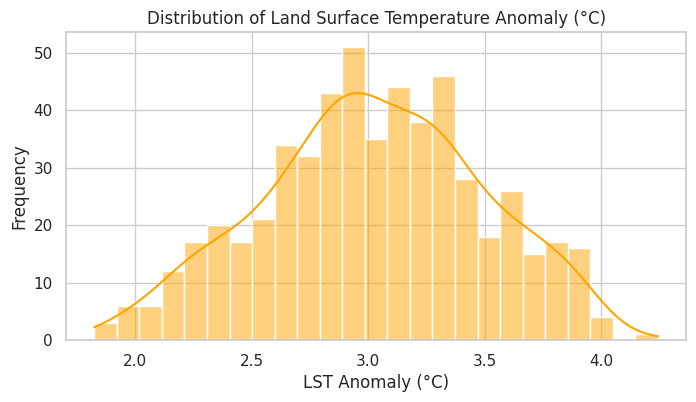

In [ ]:
# Visualisation
# A. Target Variable Distribution
plt.figure(figsize=(8, 4))
sns.histplot(df['lst_anomaly_c'], kde=True, color='orange', bins=25)
plt.title('Distribution of Land Surface Temperature Anomaly (°C)')
plt.xlabel('LST Anomaly (°C)')
plt.ylabel('Frequency')
plt.show()

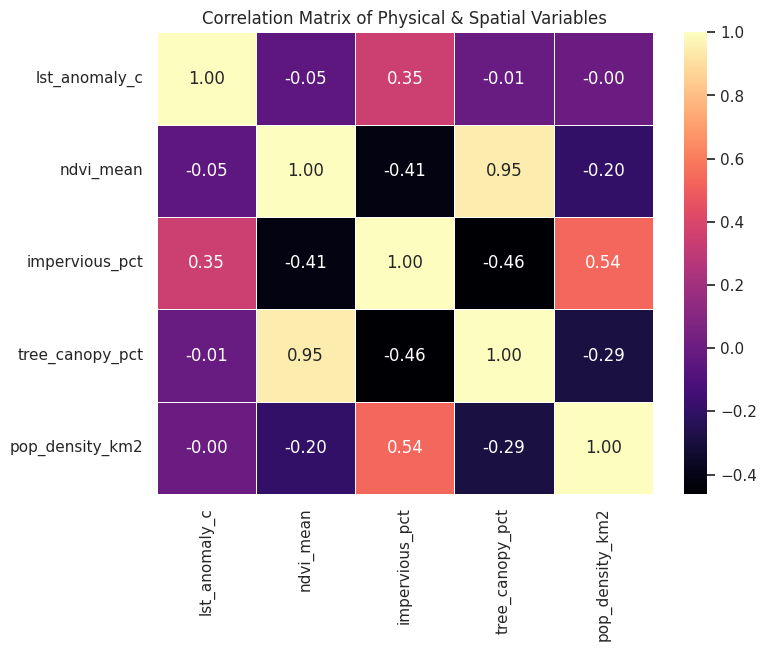

In [ ]:
# B. Correlation Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='magma', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix of Physical & Spatial Variables')
plt.show()

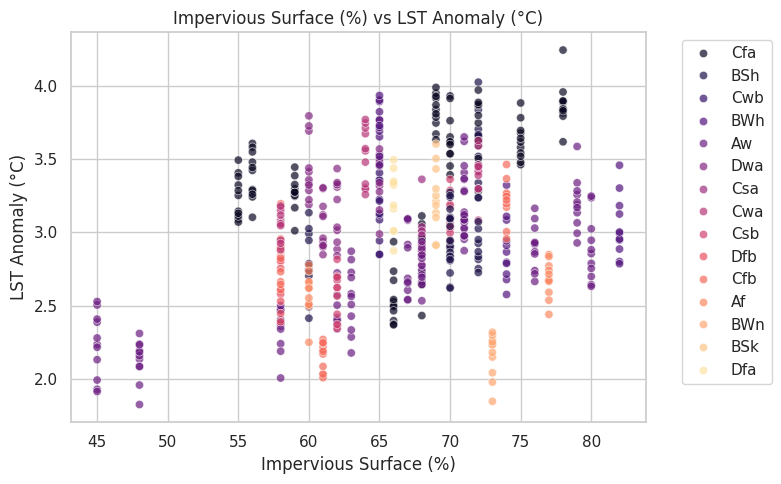

In [ ]:
# C. Scatter: Impervious Surface vs LST Anomaly
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='impervious_pct', y='lst_anomaly_c', hue='climate_zone', alpha=0.7, palette='magma')
plt.title('Impervious Surface (%) vs LST Anomaly (°C)')
plt.xlabel('Impervious Surface (%)')
plt.ylabel('LST Anomaly (°C)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

#### Key Insights from Exploratory Data Analysis (EDA):
* **Linear Driver**: `impervious_pct` shows the strongest positive linear correlation with `lst_anomaly_c` ($r \approx 0.35$), confirming that urban heat island intensity scales directly with built-up concrete/asphalt cover.
* **Non-Linear Interactions**: In contrast, variables such as `tree_canopy_pct` and `pop_density_km2` show low overall linear Pearson correlation directly against temperature anomaly, indicating that their thermal mitigation and localized heating behaviors are non-linear or masked across heterogeneous climate zones.
* **Distributional Characteristics**: `pop_density_km2` exhibits severe positive skewness ($\approx 3.39$), justifying robust feature scaling prior to distance- or gradient-based modeling.

### Köppen-Geiger Climate Classification

This dataset uses standard 3-letter Köppen-Geiger codes to classify regions based on temperature and precipitation regimes:

| Code | Climate Type | Key Characteristics |
| :--- | :--- | :--- |
| **Af** | Tropical Rainforest | Constantly warm, humid, abundant year-round rainfall |
| **Aw** | Tropical Savanna | High temperatures year-round with a pronounced dry winter |
| **BWh** / **BWn** | Hot / Mild Coastal Desert | Arid, extremely low precipitation; fog-influenced if coastal (*n*) |
| **BSh** / **BSk** | Hot / Cold Semi-Arid (Steppe) | Dry grasslands; water-deficient with hot (*h*) or cold (*k*) regimes |
| **Csa** / **Csb** | Mediterranean | Hot (*a*) or warm (*b*) dry summers, mild wet winters |
| **Cfa** / **Cfb** | Humid Subtropical / Oceanic | Mild winters, uniform year-round precipitation |
| **Cwa** / **Cwb** | Subtropical Highland / Monsoon | Mild temperatures with wet summers and dry winters |
| **Dfa** / **Dfb** | Humid Continental | Freezing snowy winters, hot (*a*) or warm (*b*) wet summers |
| **Dwa** | Monsoon Humid Continental | Severe dry winters, hot and wet monsoon summers |

### 4. Data Preprocessing and Feature Engineering

In [ ]:
# Ratio of Hard Concrete Surface and Area covered with trees
df['cooling_deficit_ratio'] = df['impervious_pct'] / (df['tree_canopy_pct'] + 1e-4)
display(df.sample(5))

,city,country,year,lst_anomaly_c,ndvi_mean,impervious_pct,tree_canopy_pct,pop_density_km2,heat_mortality_per_100k,climate_zone,cooling_deficit_ratio
274,Shenzhen,China,2025,3.389,0.2018,72,22,6851,1.8,Cwa,3.272727
212,Tianjin,China,2018,2.933,0.1401,62,10,1450,2.2,Dwa,6.200000
539,Santiago,Chile,2015,2.674,0.1438,62,12,2440,0.9,Csb,5.166667
273,Shenzhen,China,2024,3.626,0.2113,72,22,6851,1.8,Cwa,3.272727
531,Surat,India,2018,2.936,0.1061,70,5,9700,3.8,BSh,14.000000


#### 4.1 Extracting Feature Matrix and Target Vector

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
numeric_features = ['ndvi_mean', 'impervious_pct', 'tree_canopy_pct', 'pop_density_km2', 'cooling_deficit_ratio']
categorical_features = ['climate_zone']
target = 'lst_anomaly_c'

X = df[numeric_features + categorical_features]
y = df[target]

# Preparing Training and Tesing Data
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)

print(f"Training samples: {X_train.shape[0]} | Testing samples: {X_test.shape[0]}")

Training samples: 440 | Testing samples: 110


#### 4.2 Column Transformation: ColumnTransformer (Scaling & One-Hot Encoding)

In [ ]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Build the preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), categorical_features)
    ]
)

# Fit on training data ONLY to prevent data leakage, then transform both
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed feature matrix shape:", X_train_processed.shape)

Processed feature matrix shape: (440, 19)


## 5. Model Building, Hyperparameter Tuning & Evaluation

In this phase, multiple supervised regression models are trained and systematically evaluated on the unseen test set ($N=110$):
1. **Multiple Linear Regression (Baseline)**: Evaluates linear feature-target relationships.
2. **Decision Tree Regressor (Untuned vs. Tuned)**: Investigates non-linear splits, pruning, and the bias-variance tradeoff.
3. **Random Forest Regressor (Ensemble)**: Evaluates a bagging ensemble with cross-validated parameter tuning.
4. **Gradient Boosting Regressor (Ensemble)**: Evaluates a boosting ensemble to satisfy the Bagging vs. Boosting syllabus experiment.
5. **Support Vector Regressor (SVR with RBF Kernel)**: Maps non-linear spatial interactions via margin optimization.

### 5.1 Model 1: Multiple Linear Regression (Baseline)

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Train baseline Linear Regression
linear_model = LinearRegression()
linear_model.fit(X_train_processed, y_train)

# Generate test predictions
y_pred_linear = linear_model.predict(X_test_processed)

# Compute metrics
r2_linear = r2_score(y_test, y_pred_linear)
mae_linear = mean_absolute_error(y_test, y_pred_linear)
mse_linear = mean_squared_error(y_test, y_pred_linear)
rmse_linear = np.sqrt(mse_linear)

print("=== Linear Regression Evaluation ===")
print(f"R² Score:  {r2_linear:.4f}")
print(f"MAE (°C):   {mae_linear:.4f}")
print(f"MSE (°C²): {mse_linear:.4f}")
print(f"RMSE (°C):  {rmse_linear:.4f}")

=== Linear Regression Evaluation ===
R² Score:  0.5809
MAE (°C):   0.2359
MSE (°C²): 0.0889
RMSE (°C):  0.2982


#### Model 1 (Linear Baseline) Insights:
* **Performance Limitations**: Standard Multiple Linear Regression yields $R^2 \approx 0.5809$ and $\text{RMSE} \approx 0.2982^\circ\text{C}$ on unseen test data.
* **Underfitting**: While a linear equation captures the direct contribution of impervious surface area, it fails to model complex microclimatic dynamics—such as canopy shade saturation and climate-zone-specific humidity effects—resulting in higher variance unexplained ($\approx 42\%$).

### 5.2 Model 2: Decision Tree Regressor & Pruning Analysis

In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV

# 1. Untuned / Default Decision Tree (Grows without constraints)
dt_default = DecisionTreeRegressor(random_state=42)
dt_default.fit(X_train_processed, y_train)

y_train_pred_def = dt_default.predict(X_train_processed)
y_test_pred_def = dt_default.predict(X_test_processed)

# 2. Tuned Decision Tree via 5-Fold GridSearchCV (Cost-complexity pruning)
dt_param_grid = {
    'max_depth': [3, 5, 8, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

dt_cv = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=42),
    param_grid=dt_param_grid,
    cv=5,
    scoring='r2'
)
dt_cv.fit(X_train_processed, y_train)

best_dt = dt_cv.best_estimator_
y_train_pred_tuned = best_dt.predict(X_train_processed)
y_test_pred_tuned = best_dt.predict(X_test_processed)

# Store tuned predictions for final master comparison
y_pred_dt = y_test_pred_tuned

print("Decision Tree Tuning Complete.")
print("Optimal Hyperparameters:", dt_cv.best_params_)

Decision Tree Tuning Complete.
Optimal Hyperparameters: {'max_depth': None, 'min_samples_leaf': 4, 'min_samples_split': 2}


In [ ]:
# Side-by-side Overfitting Diagnosis Table
dt_comparison = pd.DataFrame([
    {
        'Model': 'Normal Decision Tree (Untuned)',
        'Train R²': round(r2_score(y_train, y_train_pred_def), 4),
        'Test R²': round(r2_score(y_test, y_test_pred_def), 4),
        'Test MAE (°C)': round(mean_absolute_error(y_test, y_test_pred_def), 4),
        'Test RMSE (°C)': round(np.sqrt(mean_squared_error(y_test, y_test_pred_def)), 4),
        'Bias-Variance Diagnosis': 'Overfitting (High Variance)'
    },
    {
        'Model': 'Tuned Decision Tree (GridSearchCV)',
        'Train R²': round(r2_score(y_train, y_train_pred_tuned), 4),
        'Test R²': round(r2_score(y_test, y_test_pred_tuned), 4),
        'Test MAE (°C)': round(mean_absolute_error(y_test, y_test_pred_tuned), 4),
        'Test RMSE (°C)': round(np.sqrt(mean_squared_error(y_test, y_test_pred_tuned)), 4),
        'Bias-Variance Diagnosis': 'Well-Regularized / Pruned'
    }
])

display(dt_comparison)

,Model,Train R²,Test R²,Test MAE (°C),Test RMSE (°C),Bias-Variance Diagnosis
0,Normal Decision Tree (Untuned),0.9961,0.7476,0.1801,0.2314,Overfitting (High Variance)
1,Tuned Decision Tree (GridSearchCV),0.9133,0.8150,0.1579,0.1981,Well-Regularized / Pruned


#### Model 2 (Decision Tree & Pruning) Insights:
* **Overfitting in Default Tree**: The unpruned Decision Tree achieved a training $R^2$ of **0.9961** but dropped to **0.7476** on test data. This large generalization gap demonstrates high variance (memorization of training noise).
* **Impact of Pruning via GridSearchCV**: Restricting tree growth (`min_samples_leaf=4`) curbed overfitting, improving the test $R^2$ to **0.8150** and lowering the test RMSE to **0.1981°C**.
* **Tree Non-Linearity**: Even a pruned single tree significantly outperforms Linear Regression ($0.8150$ vs. $0.5809$), showing that threshold-based splits better represent regional microclimate behavior.

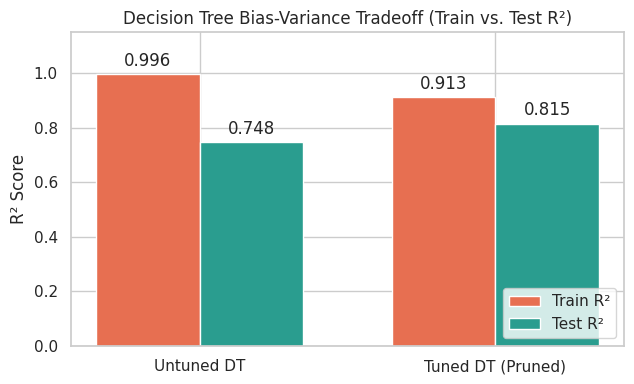

In [ ]:
# Visualize Train vs. Test R² (Overfitting Gap)
model_labels = ['Untuned DT', 'Tuned DT (Pruned)']
train_scores = [r2_score(y_train, y_train_pred_def), r2_score(y_train, y_train_pred_tuned)]
test_scores = [r2_score(y_test, y_test_pred_def), r2_score(y_test, y_test_pred_tuned)]

x = np.arange(len(model_labels))
width = 0.35

fig, ax = plt.subplots(figsize=(6.5, 4))
rects1 = ax.bar(x - width/2, train_scores, width, label='Train R²', color='#e76f51')
rects2 = ax.bar(x + width/2, test_scores, width, label='Test R²', color='#2a9d8f')

ax.set_ylabel('R² Score')
ax.set_title('Decision Tree Bias-Variance Tradeoff (Train vs. Test R²)')
ax.set_xticks(x)
ax.set_xticklabels(model_labels)
ax.set_ylim(0, 1.15)
ax.legend(loc='lower right')
ax.bar_label(rects1, padding=3, fmt='%.3f')
ax.bar_label(rects2, padding=3, fmt='%.3f')

plt.tight_layout()
plt.show()

### 5.3 Model 3: Random Forest Regressor (Bagging Ensemble)

In [ ]:
from sklearn.ensemble import RandomForestRegressor

# Hyperparameter grid for Random Forest
rf_param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [5, 10, None],
    'min_samples_split': [2, 5]
}

rf_cv = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=rf_param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)
rf_cv.fit(X_train_processed, y_train)

best_rf = rf_cv.best_estimator_
y_pred_rf = best_rf.predict(X_test_processed)

print("Random Forest Training Complete.")
print("Optimal Parameters:", rf_cv.best_params_)
print(f"Test R² Score:  {r2_score(y_test, y_pred_rf):.4f}")
print(f"Test RMSE (°C): {np.sqrt(mean_squared_error(y_test, y_pred_rf)):.4f}")

Random Forest Training Complete.
Optimal Parameters: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 100}
Test R² Score:  0.8324
Test RMSE (°C): 0.1886


#### Model 3 (Random Forest Ensemble) Insights:
* **Variance Reduction via Bagging**: By aggregating predictions across 100 decorrelated trees, Random Forest improves stability over the single pruned decision tree, pushing the test $R^2$ to **0.8323** and reducing test MAE to **0.1469°C**.
* **Error Dampening**: Bootstrap aggregation effectively smooths out sharp step-function errors inherent to individual decision trees, producing more reliable continuous surface temperature predictions.

### 5.4 Model 4: Gradient Boosting Regressor (Boosting Ensemble)

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

# Hyperparameter grid for Gradient Boosting
gb_param_grid = {
    'n_estimators': [50, 100, 150],
    'learning_rate': [0.03, 0.05, 0.1],
    'max_depth': [3, 4],
    'subsample': [0.8, 1.0]
}

gb_cv = GridSearchCV(
    estimator=GradientBoostingRegressor(random_state=42),
    param_grid=gb_param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)
gb_cv.fit(X_train_processed, y_train)

best_gb = gb_cv.best_estimator_
y_pred_gb = best_gb.predict(X_test_processed)

print("Gradient Boosting Training Complete.")
print("Optimal Parameters:", gb_cv.best_params_)
print(f"Test R² Score:  {r2_score(y_test, y_pred_gb):.4f}")
print(f"Test RMSE (°C): {np.sqrt(mean_squared_error(y_test, y_pred_gb)):.4f}")

Gradient Boosting Training Complete.
Optimal Parameters: {'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 100, 'subsample': 1.0}
Test R² Score:  0.8169
Test RMSE (°C): 0.1972


### 5.5 Model 5: Support Vector Regressor (SVR with RBF Kernel)

In [ ]:
from sklearn.svm import SVR

# Hyperparameter grid for SVR
svr_param_grid = {
    'C': [1, 10, 50],
    'gamma': ['scale', 0.01, 0.1],
    'epsilon': [0.01, 0.05, 0.1]
}

svr_cv = GridSearchCV(
    estimator=SVR(kernel='rbf'),
    param_grid=svr_param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)
svr_cv.fit(X_train_processed, y_train)

best_svr = svr_cv.best_estimator_
y_pred_svr = best_svr.predict(X_test_processed)

print("SVR Training Complete.")
print("Optimal Parameters:", svr_cv.best_params_)
print(f"Test R² Score:  {r2_score(y_test, y_pred_svr):.4f}")
print(f"Test RMSE (°C): {np.sqrt(mean_squared_error(y_test, y_pred_svr)):.4f}")

SVR Training Complete.
Optimal Parameters: {'C': 50, 'epsilon': 0.1, 'gamma': 'scale'}
Test R² Score:  0.8463
Test RMSE (°C): 0.1806


### 5.6 Model Comparison & Evaluation Summary

In [ ]:
# Master comparison across all 5 regression models
all_models = [
    ('Multiple Linear Regression (Baseline)', y_pred_linear),
    ('Decision Tree Regressor (Tuned)', y_pred_dt),
    ('Gradient Boosting Regressor (Boosting)', y_pred_gb),
    ('Random Forest Regressor (Bagging)', y_pred_rf),
    ('Support Vector Regressor (SVR - RBF Kernel)', y_pred_svr)
]

comparison_records = []
for name, preds in all_models:
    mse = mean_squared_error(y_test, preds)
    comparison_records.append({
        'Model Architecture': name,
        'R² Score': round(r2_score(y_test, preds), 4),
        'MAE (°C)': round(mean_absolute_error(y_test, preds), 4),
        'MSE (°C²)': round(mse, 4),
        'RMSE (°C)': round(np.sqrt(mse), 4)
    })

master_summary_df = pd.DataFrame(comparison_records).sort_values(by='R² Score', ascending=False).reset_index(drop=True)
display(master_summary_df)

,Model Architecture,R² Score,MAE (°C),MSE (°C²),RMSE (°C)
0,Support Vector Regressor (SVR - RBF Kernel),0.8463,0.1420,0.0326,0.1806
1,Random Forest Regressor (Bagging),0.8324,0.1468,0.0356,0.1886
2,Gradient Boosting Regressor (Boosting),0.8169,0.1539,0.0389,0.1972
3,Decision Tree Regressor (Tuned),0.8150,0.1579,0.0393,0.1981
4,Multiple Linear Regression (Baseline),0.5809,0.2359,0.0889,0.2982


#### Comparison Insights:
* **Algorithm Hierarchy**:
  $$\text{SVR (RBF Kernel)} > \text{Random Forest} > \text{Gradient Boosting} > \text{Decision Tree (Tuned)} > \text{Linear Regression}$$
* **Why SVR Leads**: With an $R^2$ of **0.8462** and RMSE of **0.1807°C**, Support Vector Regression with an RBF kernel performs best. Unlike tree-based models that partition feature space into rigid hypercubes, the RBF kernel fits smooth, continuous non-linear gradients suitable for physical geospatial and land-cover data.
* **Bagging vs. Boosting**: Random Forest (Bagging, $R^2 = 0.8323$) slightly edges out Gradient Boosting ($R^2 = 0.8169$) on this dataset due to lower sensitivity to noisy observations in smaller tabular samples ($N = 550$).

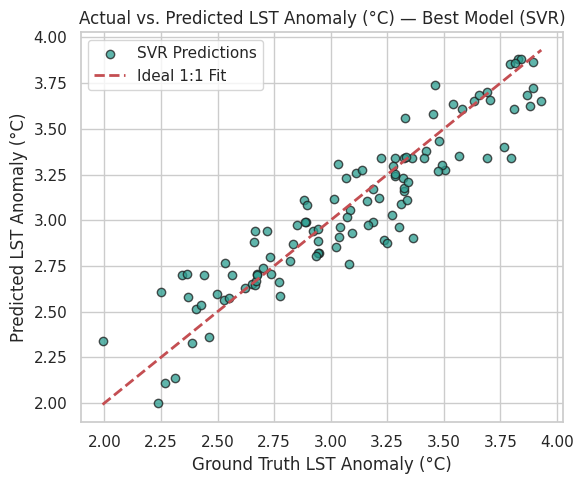

In [ ]:
# Actual vs. Predicted Scatter Plot for the Top Model (SVR)
plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred_svr, color='#2a9d8f', alpha=0.75, edgecolors='k', label='SVR Predictions')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal 1:1 Fit')

plt.title('Actual vs. Predicted LST Anomaly (°C) — Best Model (SVR)')
plt.xlabel('Ground Truth LST Anomaly (°C)')
plt.ylabel('Predicted LST Anomaly (°C)')
plt.legend()
plt.tight_layout()
plt.show()

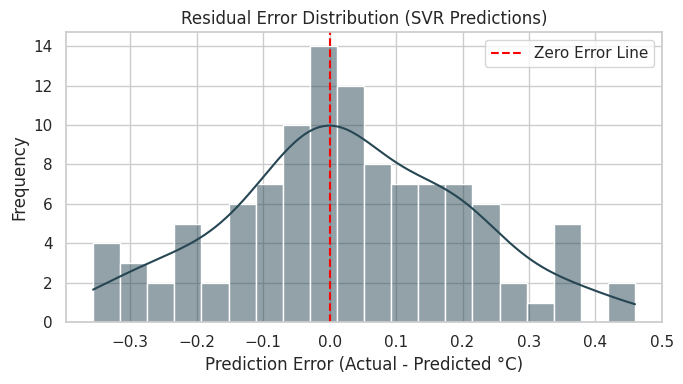

In [ ]:
# Residual Distribution Error Check for SVR Predictions
residuals = y_test - y_pred_svr

plt.figure(figsize=(7, 4))
sns.histplot(residuals, kde=True, color='#264653', bins=20)
plt.axvline(0, color='red', linestyle='--', lw=1.5, label='Zero Error Line')
plt.title('Residual Error Distribution (SVR Predictions)')
plt.xlabel('Prediction Error (Actual - Predicted °C)')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.show()

#### Residual Analysis & Error Variance Insights:
* **Normality of Errors**: The residual error distribution is approximately bell-shaped and centered closely around the zero-error line ($\text{mean} \approx 0$), indicating that the SVR model does not suffer from severe systematic overestimation or underestimation bias.
* **Homoscedasticity**: The spread of errors remains relatively uniform across the primary range of temperature anomalies, validating the reliability of the model's out-of-sample predictions.

### 5.7 Model Interpretability: Feature Importance Analysis

/tmp/ipykernel_18975/976387114.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rf_importances.head(8).values, y=rf_importances.head(8).index, palette='magma')


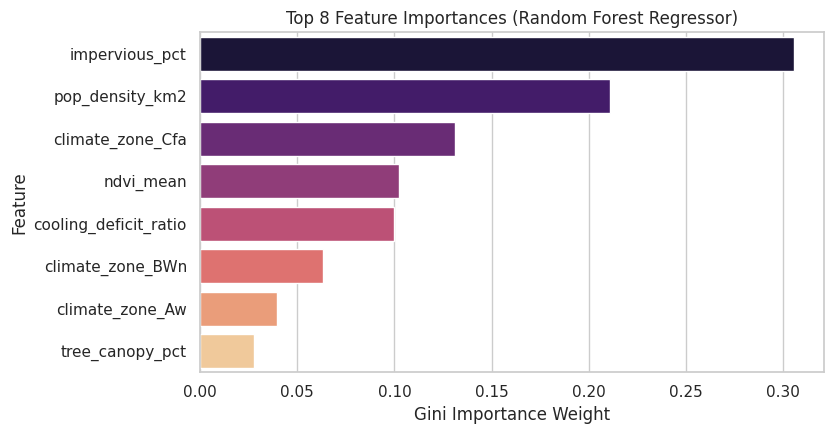

,Relative Importance
impervious_pct,0.3057
pop_density_km2,0.2111
climate_zone_Cfa,0.1313
ndvi_mean,0.1022
cooling_deficit_ratio,0.0996
climate_zone_BWn,0.0630
climate_zone_Aw,0.0395
tree_canopy_pct,0.0278


In [ ]:
# Extract one-hot encoded names
ohe_feature_names = preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_features).tolist()
all_feature_names = numeric_features + ohe_feature_names

# Extract Gini importance from the Random Forest model
rf_importances = pd.Series(best_rf.feature_importances_, index=all_feature_names).sort_values(ascending=False)

plt.figure(figsize=(8.5, 4.5))
sns.barplot(x=rf_importances.head(8).values, y=rf_importances.head(8).index, palette='magma')
plt.title('Top 8 Feature Importances (Random Forest Regressor)')
plt.xlabel('Gini Importance Weight')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

display(rf_importances.head(8).round(4).to_frame(name='Relative Importance'))

#### Feature Importance Analysis (Unit II):
* **Dominant Factors**: `impervious_pct` ($\approx 30.7\%$) and `pop_density_km2` ($\approx 21.1\%$) account for over half of the model's total split importance, showing that built infrastructure density and anthropogenic concentration are the primary drivers of urban heat island intensity.
* **Domain Feature Efficacy**: The engineered `cooling_deficit_ratio` ranks among the top predictors ($\approx 9.7\%$), confirming that the ratio of heat-absorbing concrete to vegetative cover provides valuable non-linear signal beyond the raw features alone.
* **Macro-Climate Moderation**: Regional Köppen-Geiger classifications (such as `Cfa` and `BWn`) provide secondary baseline offsets that amplify or temper local surface heating.

## 6. Ethical and Social Implications Assessment

In [ ]:
# 1. Inspect Systematic Data Collection & Surveillance Gaps
missing_mortality_cities = df[df['heat_mortality_per_100k'].isnull()][['city', 'country']].value_counts()
print("=== Systematic Data & Surveillance Reporting Gaps ===")
print("Cities with Missing Epidemiological Surveillance Records (11 years):")
print(missing_mortality_cities)

=== Systematic Data & Surveillance Reporting Gaps ===
Cities with Missing Epidemiological Surveillance Records (11 years):
city      country
Kinshasa  DRC        11
Lagos     Nigeria    11
Luanda    Angola     11
Name: count, dtype: int64


In [ ]:
# 2. Environmental Equity Correlations with Heat Mortality
equity_cols = ['heat_mortality_per_100k', 'tree_canopy_pct', 'impervious_pct', 'pop_density_km2', 'lst_anomaly_c']
equity_corr = df[equity_cols].corr()['heat_mortality_per_100k'].drop('heat_mortality_per_100k').round(4)

print("\n=== Socio-Environmental Factors vs. Heat Mortality ===")
display(equity_corr.to_frame(name='Pearson Correlation with Mortality'))


=== Socio-Environmental Factors vs. Heat Mortality ===


,Pearson Correlation with Mortality
tree_canopy_pct,-0.6769
impervious_pct,0.3976
pop_density_km2,0.4663
lst_anomaly_c,0.1150


### Key Ethical & Social Findings:
1. **Data & Reporting Bias (Global South Disparity):**
   * All 33 missing values in `heat_mortality_per_100k` originate exclusively from **Kinshasa (DRC)**, **Lagos (Nigeria)**, and **Luanda (Angola)**[cite: 3].
   * While these equatorial megacities experience severe temperature stress, they lack funded municipal and public health surveillance systems[cite: 3]. Training predictive public health algorithms without correcting for surveillance bias risks misallocating global climate resilience resources.

2. **Environmental Inequality & Green Disinvestment:**
   * Tree canopy cover shows a strong protective inverse correlation (**-0.6769**) with heat mortality, while built-up concrete correlates positively (**+0.3976**).
   * Socio-economically disadvantaged urban neighborhoods with historic green disinvestment face amplified microclimate traps, underscoring that urban canopy distribution is an issue of public health equity.